In [3]:

import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
from matplotlib.pyplot import scatter




project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

import cardio.visualization.eda as eda
from cardio.features import add_features, get_feature, categorizar_pressao

importlib.reload(eda)



<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<module 'cardio.visualization.eda' from 'c:\\Users\\miche\\OneDrive\\Documentos\\Python\\Cardio\\src\\cardio\\visualization\\eda.py'>

In [4]:
descricao = {
    "id": "Identificador do paciente",
    "age": "Idade",
    "gender": "Sexo",
    "height": "Altura (cm)",
    "weight": "Peso (kg)",
    "ap_hi": "Pressão arterial sistólica (mmHg)",
    "ap_lo": "Pressão arterial diastólica (mmHg)",
    "cholesterol": "Nível de colesterol",
    "gluc": "Nível de glicose",
    "smoke": "Tabagismo",
    "alco": "Consumo de álcool",
    "active": "Prática de atividade física",
    "cardio": "Presença de doença cardiovascular",
    "imc": "Índice de Massa Corporal (kg/m²)"
}

In [5]:
df = pd.read_csv("../data/raw/cardio_train.csv", sep=";")

#Limpeza de dados
df.isnull().sum()

#Covertendo idade de dias para anos e criando coluna de IMC
df["age"] = (df["age"] / 365.25).astype(int)
df["imc"] = df["weight"] / (df["height"] / 100) ** 2

#Pre-processamento de dados
df= df.drop(columns=["id","weight"])

#Verificando dados - valores inválidos de pressão arterial

print ("Pressão arterial diastólica menor que zero:", (df["ap_lo"] <= 0).sum())
print ("Pressão arterial sistólica menor que zero:", (df["ap_hi"] <= 0).sum())
print ("Pressão arterial diastólica maior que a sistólica:", (df["ap_lo"] >= df["ap_hi"]).sum())
print ("Pressão arterial maior que 300/200:", ((df["ap_hi"] >= 300) & (df["ap_lo"] >= 200)).sum())


dados_invalidos = (
    (df["ap_hi"] <= 0) |
    (df["ap_lo"] <= 0) |
    (df["ap_lo"] >= df["ap_hi"]) |
    (df["ap_hi"] >= 300) |
    (df["ap_lo"] >= 200) |
    (df["ap_hi"] < 70) |
    (df["ap_lo"] < 40)
)

df_clean = df.loc[~dados_invalidos].copy()

print("Total original:", len(df))
print("Dados removidos:", len(df) - len(df_clean))
print("Dados limpos:", len(df_clean))


Pressão arterial diastólica menor que zero: 22
Pressão arterial sistólica menor que zero: 7
Pressão arterial diastólica maior que a sistólica: 1236
Pressão arterial maior que 300/200: 0
Total original: 70000
Dados removidos: 1329
Dados limpos: 68671


In [4]:
df.info() #— tipos de dados e valores não nulos.

df.describe() #— médias, medianas, mínimos e máximos.

df.isnull().sum() #— valores ausentes.

df.duplicated().sum() #— registros duplicados.

df["cardio"].value_counts() #— distribuição do target.

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          70000 non-null  int64  
 1   gender       70000 non-null  int64  
 2   height       70000 non-null  int64  
 3   ap_hi        70000 non-null  int64  
 4   ap_lo        70000 non-null  int64  
 5   cholesterol  70000 non-null  int64  
 6   gluc         70000 non-null  int64  
 7   smoke        70000 non-null  int64  
 8   alco         70000 non-null  int64  
 9   active       70000 non-null  int64  
 10  cardio       70000 non-null  int64  
 11  imc          70000 non-null  float64
dtypes: float64(1), int64(11)
memory usage: 6.4 MB


cardio
0    35021
1    34979
Name: count, dtype: int64

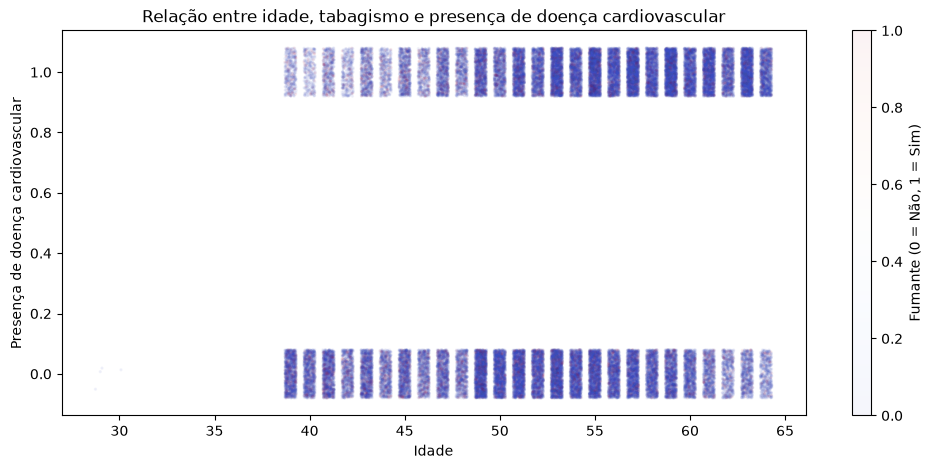

In [16]:
# 1. Idade, tabagismo e doença cardiovascular
eda.plot_idade_tabagismo_cardio(df_clean)

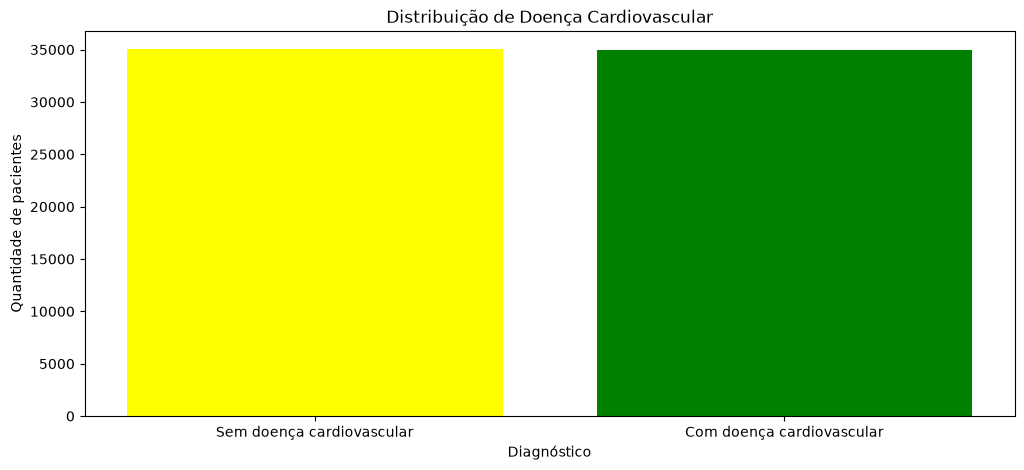

In [6]:
eda.plot_distribuicao_cardio(df)

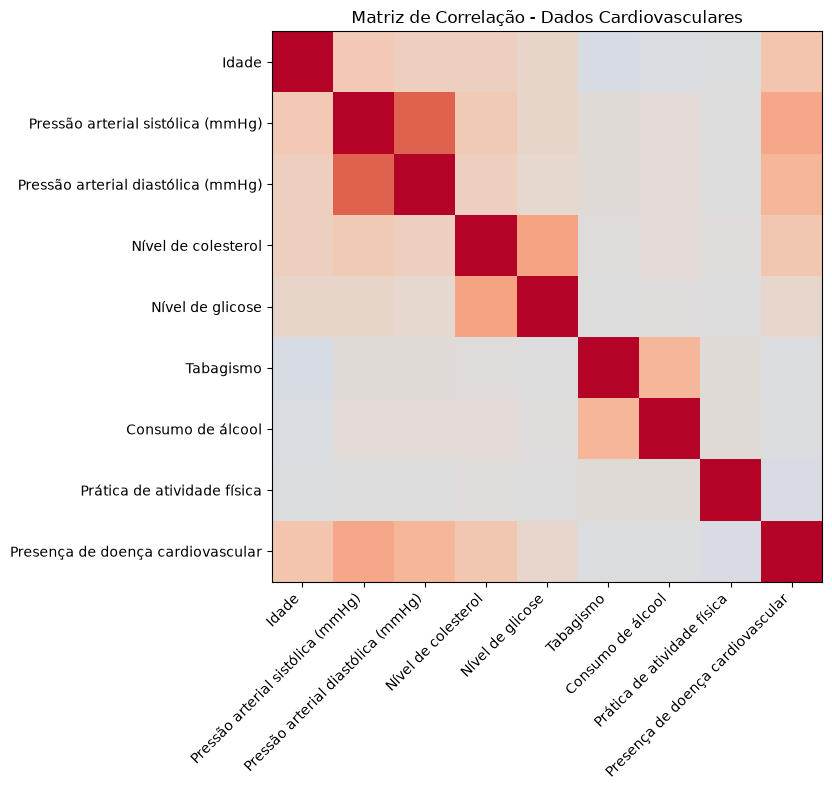

In [7]:
# 3. Matriz de correlação
eda.plot_matriz_correlacao(df_clean)

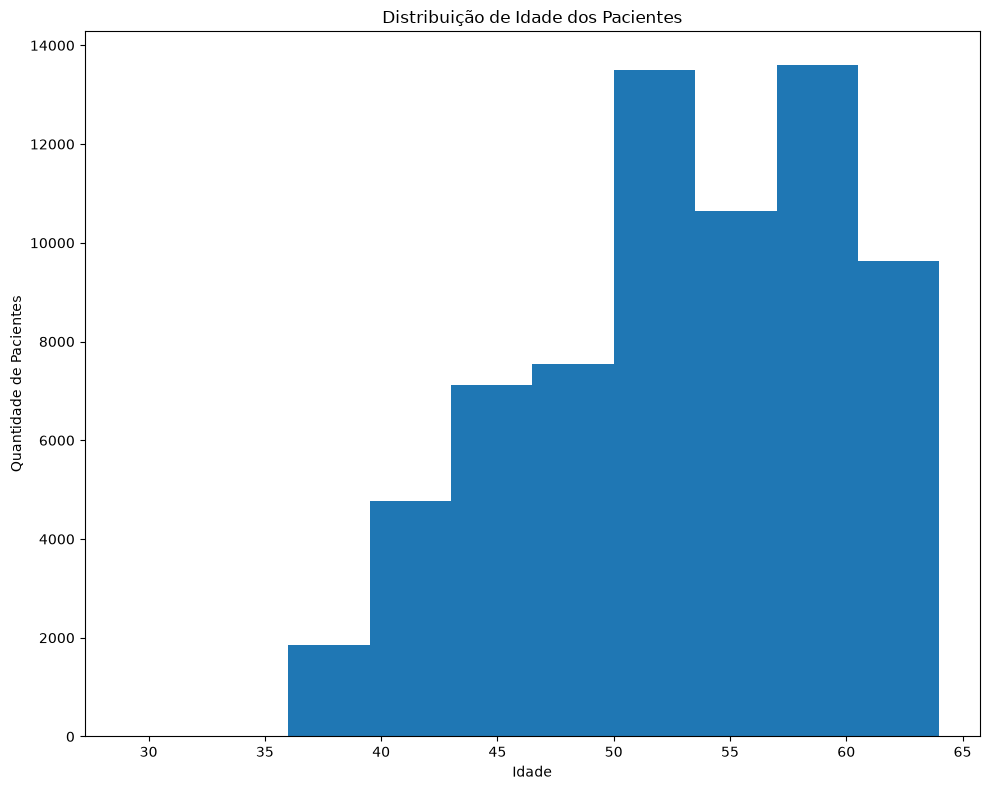

In [8]:
# 4. Distribuição de idade
eda.plot_distribuicao_idade(df_clean)

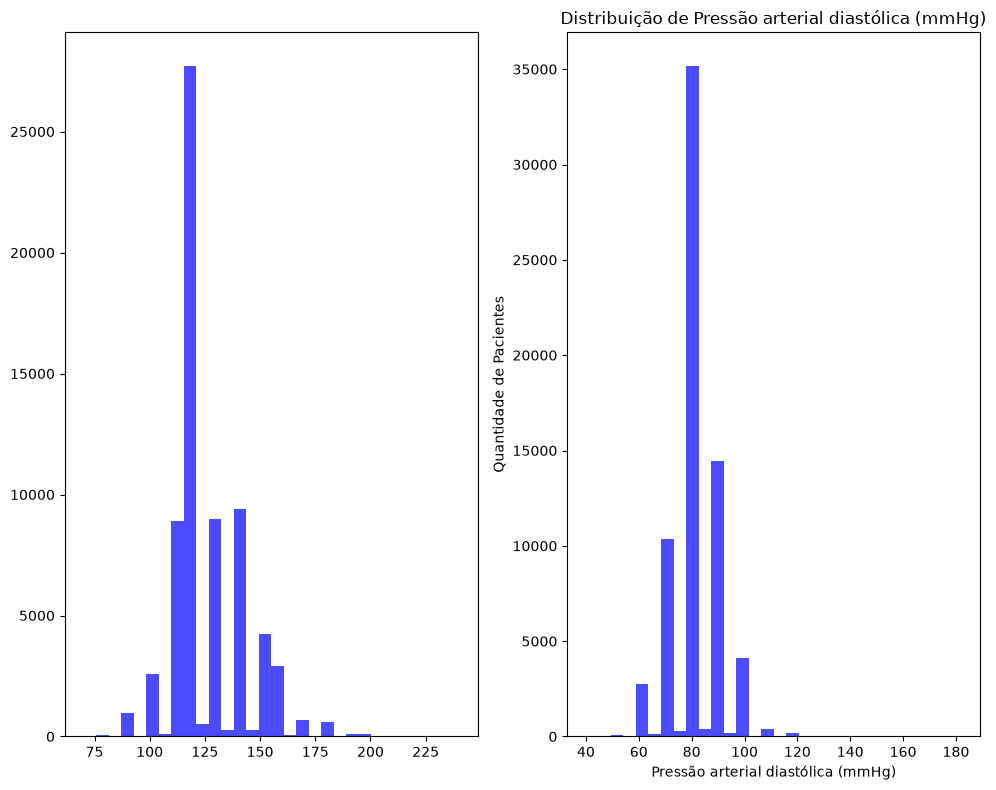

In [9]:
# 5. Distribuição das pressões sistólica e diastólica
eda.plot_distribuicao_pressao_arterial(df_clean)


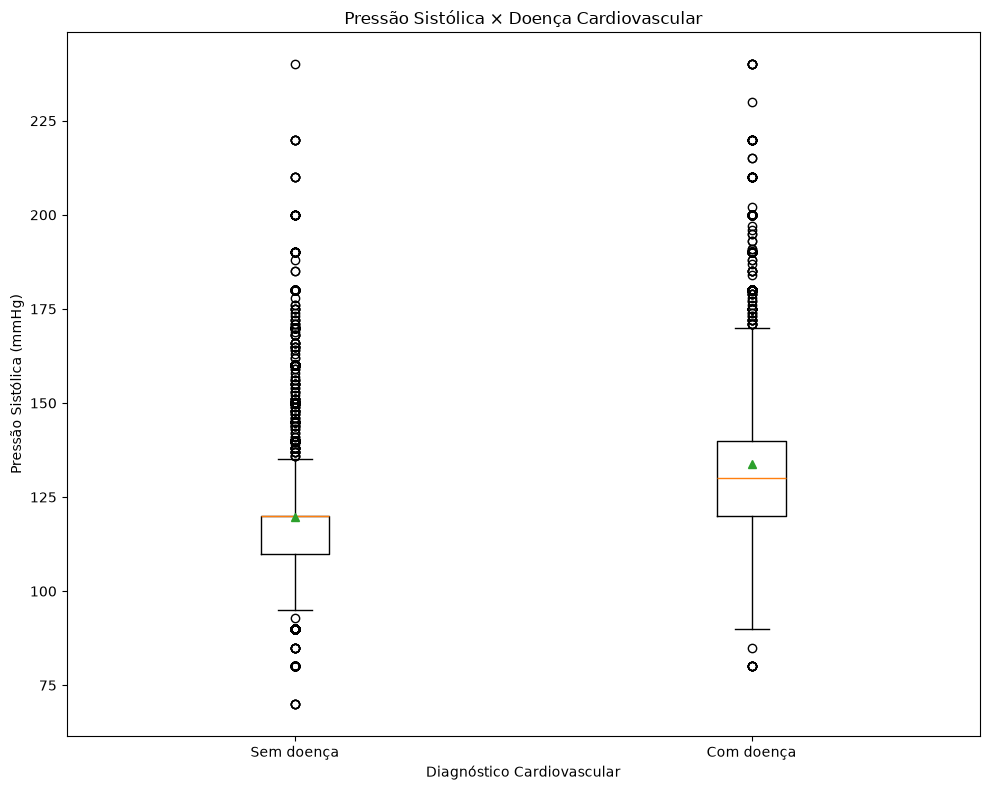

In [10]:
"""
ANÁLISE EXPLORATÓRIA - PRESSÃO SISTÓLICA × CARDIO

A pressão sistólica apresenta valores centrais mais elevados
nos pacientes com doença cardiovascular.

A mediana é aproximadamente 130 mmHg no grupo com doença,
contra 120 mmHg no grupo sem doença.

O grupo com doença apresenta maior dispersão dos valores.

Existem outliers nos dois grupos, mas valores elevados
não devem ser removidos automaticamente.

CONCLUSÃO:
Existe associação entre pressão sistólica elevada e a
presença de doença cardiovascular."""


eda.plot_pressao_sistolica_cardio(df_clean)

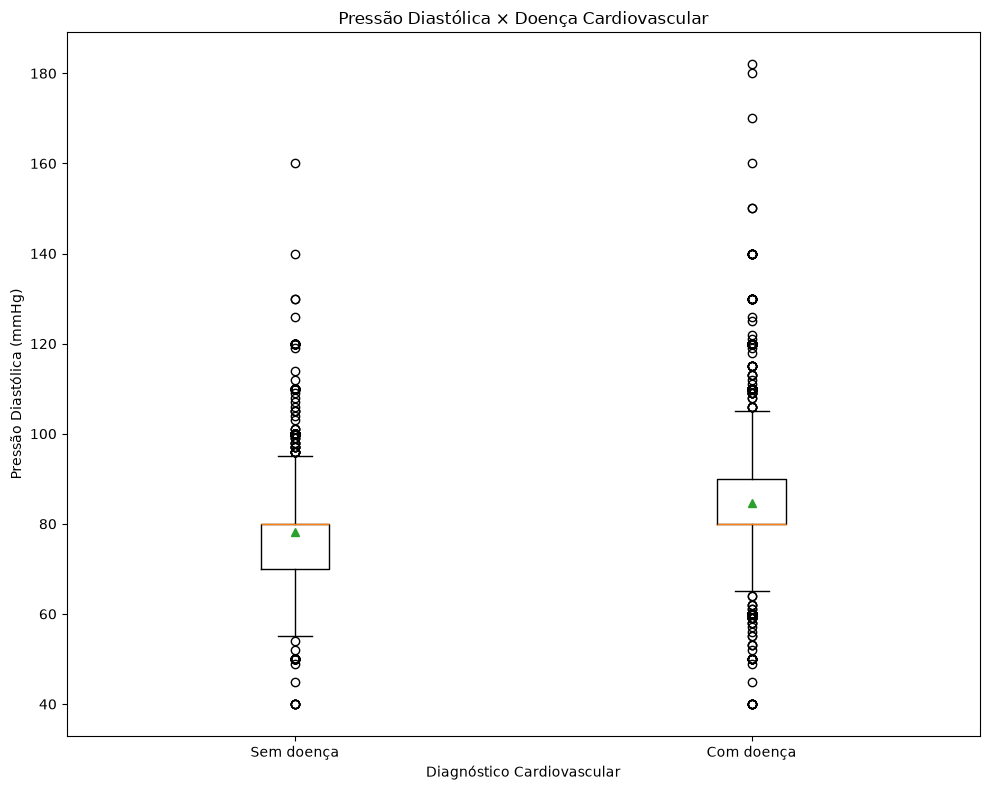

In [11]:
"""
ANÁLISE EXPLORATÓRIA (EDA)
PRESSÃO DIASTÓLICA (ap_lo) × DOENÇA CARDIOVASCULAR (cardio)

1. MÉDIA:
   Pacientes com doença cardiovascular apresentam pressão
   diastólica média aproximadamente de 85 mmHg, enquanto
   pacientes sem doença apresentam cerca de 78 mmHg.

2. MEDIANA:
   Ambos os grupos apresentam mediana próxima de 80 mmHg,
   indicando valores centrais semelhantes.

3. DISTRIBUIÇÃO:
   O grupo com doença apresenta quartis superiores aos
   observados no grupo sem doença cardiovascular.

   Sem doença: aproximadamente 70 a 80 mmHg (Q1 a Q3).
   Com doença: aproximadamente 80 a 90 mmHg (Q1 a Q3).

4. OUTLIERS:
   Existem valores extremos nos dois grupos, especialmente
   pressões superiores a 120 mmHg.

   Esses valores podem ser clinicamente possíveis e não
   devem ser removidos automaticamente.

5. QUALIDADE DOS DADOS:
   Após o pré-processamento, os valores extremamente baixos
   observados anteriormente não aparecem mais no gráfico.

CONCLUSÃO:
   A pressão arterial diastólica apresenta uma associação
   positiva com a presença de doença cardiovascular.

   O grupo com doença apresenta média mais elevada e
   distribuição deslocada para valores superiores.

   Entretanto, existe sobreposição entre os grupos,
   indicando que a pressão diastólica isoladamente não
   permite distinguir todos os pacientes.

OBSERVAÇÃO:
   Os valores apresentados são estimativas visuais do Boxplot
   e devem ser confirmados com estatísticas descritivas.
"""


eda.plot_pressao_diastolica_cardio(df_clean)

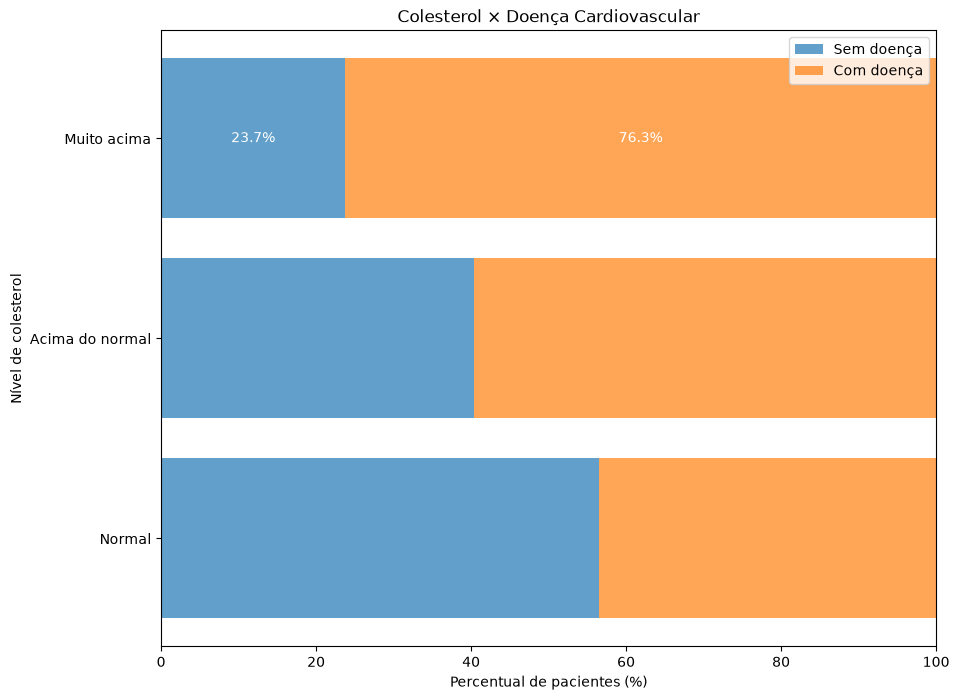

In [12]:
"""
ANÁLISE EXPLORATÓRIA (EDA)
COLESTEROL (cholesterol) × DOENÇA CARDIOVASCULAR (cardio)

1. COLESTEROL NORMAL:
   Aproximadamente 44% dos pacientes apresentam
   doença cardiovascular, enquanto 56% não apresentam.

2. COLESTEROL ACIMA DO NORMAL:
   Aproximadamente 60% dos pacientes apresentam
   doença cardiovascular.

3. COLESTEROL MUITO ACIMA DO NORMAL:
   Aproximadamente 77% dos pacientes apresentam
   doença cardiovascular.

4. ASSOCIAÇÃO:
   Observa-se um aumento progressivo na proporção
   de pacientes com doença cardiovascular conforme
   aumenta a categoria de colesterol.

5. INTERPRETAÇÃO:
   O colesterol apresenta associação com o diagnóstico
   cardiovascular e pode contribuir para a classificação
   realizada pelo modelo de Machine Learning.

CONCLUSÃO:
   Os resultados sugerem uma associação positiva entre
   níveis elevados de colesterol e presença de doença
   cardiovascular.

   Entretanto, a associação observada não implica
   causalidade e deve ser avaliada em conjunto com
   outras variáveis clínicas.

OBSERVAÇÃO:
   Percentuais estimados visualmente a partir do gráfico.
"""


eda.plot_colesterol_cardio(df_clean)




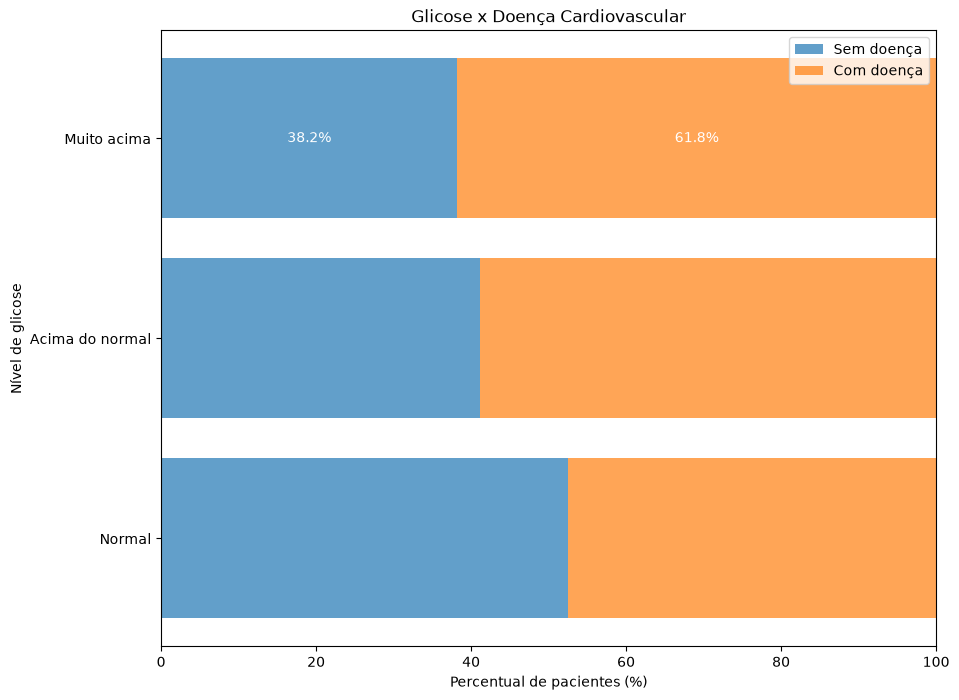

In [13]:
"""
ANÁLISE EXPLORATÓRIA (EDA)
GLICOSE (gluc) × DOENÇA CARDIOVASCULAR (cardio)

1. GLICOSE NORMAL:
   48,1% dos pacientes apresentam doença cardiovascular,
   enquanto 51,9% não apresentam.

2. GLICOSE ACIMA DO NORMAL:
   59,3% dos pacientes apresentam doença cardiovascular,
   representando um aumento de 11,2 pontos percentuais
   em relação ao grupo com glicose normal.

3. GLICOSE MUITO ACIMA DO NORMAL:
   62,2% dos pacientes apresentam doença cardiovascular,
   sendo a maior proporção entre as três categorias.

4. ASSOCIAÇÃO:
   Observa-se uma tendência de aumento na proporção
   de pacientes com doença cardiovascular conforme
   aumenta a categoria de glicose.

5. INTERPRETAÇÃO:
   A glicose pode ser uma variável relevante para
   o modelo de Machine Learning, especialmente
   quando combinada com idade, pressão arterial
   e colesterol.

CONCLUSÃO:
   Os resultados indicam associação positiva entre
   categorias mais elevadas de glicose e presença
   de doença cardiovascular.

   Entretanto, essa associação não estabelece
   causalidade nem garante importância preditiva
   da variável no modelo de classificação.

OBSERVAÇÃO:
   Percentuais obtidos do gráfico de barras proporcionais.
"""


eda.plot_glicose_cardio(df_clean)

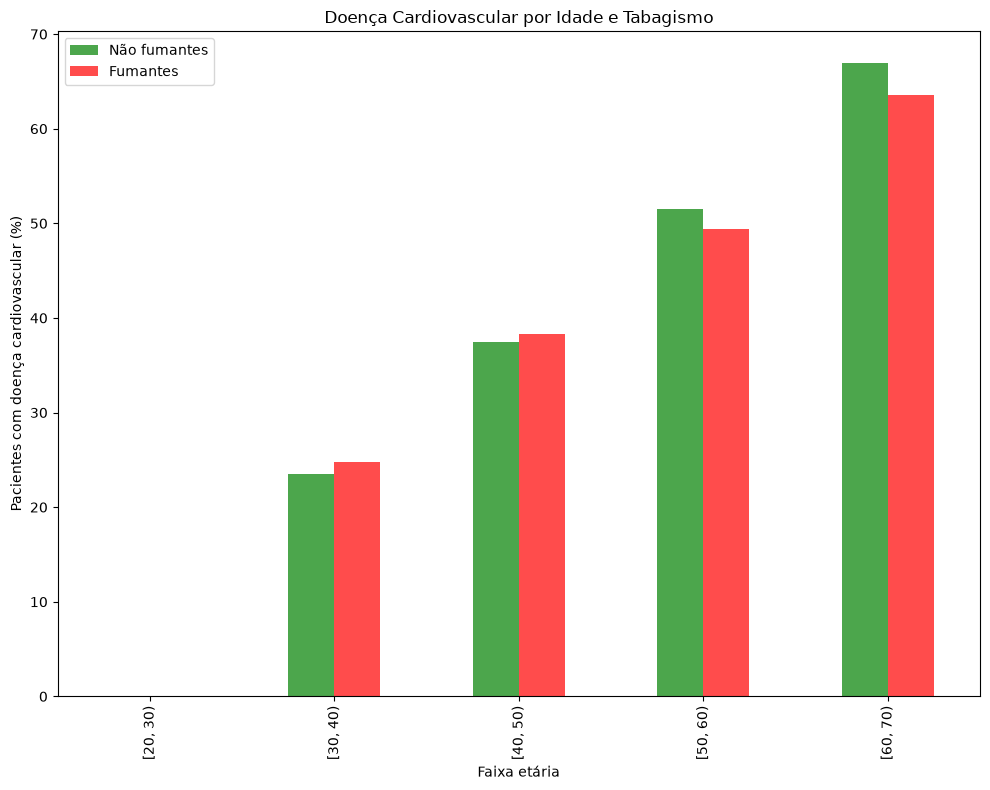

In [14]:
"""
Análise da distribuição por faixa etária e tabagismo

A amostra analisada contém 68.671 pacientes, sendo
62.630 não fumantes (91,2%) e 6.041 fumantes (8,8%).

Observa-se uma distribuição desigual entre os grupos,
com predominância de pacientes não fumantes.

A faixa etária de 20 a 29 anos apresenta apenas
três pacientes, não sendo representativa para
comparações entre fumantes e não fumantes.

O gráfico anterior demonstra que a proporção de
doença cardiovascular aumenta com a idade.

Entretanto, a relação entre tabagismo e presença
de doença cardiovascular não apresenta um padrão
uniforme entre as faixas etárias.

Portanto, não é possível concluir, apenas com essa
análise, que o tabagismo tenha maior ou menor
associação com a doença cardiovascular.

Outras variáveis deverão ser consideradas.
"""

eda.plot_faixa_etaria_tabagismo_cardio(df_clean)


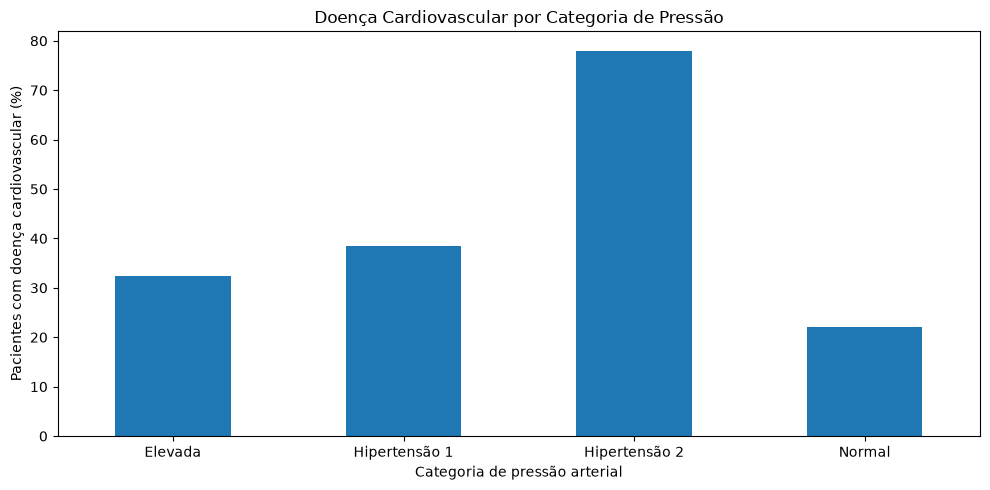

In [15]:
eda.plot_categoria_pressao_cardio(df_clean)

In [20]:
import inspect

print(inspect.getsource(eda.plot_idade_tabagismo_cardio))

def plot_idade_tabagismo_cardio(df):
    
    fig, aux = plt.subplots(figsize=(12, 5))
   
    rng = np.random.default_rng(42)

    idade_jitter = df["age"] + rng.uniform(-0.3, 0.3, len(df))
    cardio_jitter = df["cardio"] + rng.uniform(-0.08, 0.08, len(df))
  
    scatter = aux.scatter (
    x = idade_jitter,
    y = cardio_jitter,
    c=df["smoke"],
    cmap="coolwarm", 
    s=2,
    alpha=0.05
    )

    aux.set_xlabel("Idade")
    aux.set_ylabel("Presença de doença cardiovascular")
    aux.set_title("Relação entre idade, tabagismo e presença de doença cardiovascular")
    plt.colorbar(scatter, ax=aux, label="Fumante (0 = Não, 1 = Sim)")

    plt.show()

